In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, cohen_kappa_score, matthews_corrcoef
)
import joblib

# -----------------------------
# Load models
# -----------------------------
rf_model = joblib.load(r'D:\Thesis\Main\Models\Random Forest\New Final\RF_Final_Model.pkl')
xgb_model = joblib.load(r'D:\Thesis\Main\Models\XGBoost\XGBoost_Final_Model.pkl')

# -----------------------------
# Load dataset
# -----------------------------
df = pd.read_excel(r'D:\Thesis\Main\Data\GW table\Dataset_binary1.xlsx')
feature_cols = ['Rainfall', 'Soil', 'Geology', 'DEM', 'Drainage_Density',
                'Slope', 'Lineament_Density', 'LULC', 'TWI']

X = df[feature_cols].values
y = df['Recharge_Class'].values  # Binary: 0 = Low, 1 = High

# -----------------------------
# Train-test split
# -----------------------------
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# -----------------------------
# Predictions
# -----------------------------
rf_pred = rf_model.predict(X_test)
xgb_pred = xgb_model.predict(X_test)

# Probabilities (take only positive class)
rf_pred_proba = rf_model.predict_proba(X_test)[:, 1]
xgb_pred_proba = xgb_model.predict_proba(X_test)[:, 1]

# -----------------------------
# Calculate metrics
# -----------------------------
metrics = {
    'Model': ['Random Forest', 'XGBoost'],
    'Accuracy': [
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, xgb_pred)
    ],
    'Precision': [
        precision_score(y_test, rf_pred, average='weighted'),
        precision_score(y_test, xgb_pred, average='weighted')
    ],
    'Recall': [
        recall_score(y_test, rf_pred, average='weighted'),
        recall_score(y_test, xgb_pred, average='weighted')
    ],
    'F1-Score': [
        f1_score(y_test, rf_pred, average='weighted'),
        f1_score(y_test, xgb_pred, average='weighted')
    ],
    'ROC AUC': [
        roc_auc_score(y_test, rf_pred_proba),   # Binary
        roc_auc_score(y_test, xgb_pred_proba)   # Binary
    ],
    'Kappa': [
        cohen_kappa_score(y_test, rf_pred),
        cohen_kappa_score(y_test, xgb_pred)
    ],
    'MCC': [
        matthews_corrcoef(y_test, rf_pred),
        matthews_corrcoef(y_test, xgb_pred)
    ],
    'OOB Error': [
        1 - rf_model.oob_score_ if hasattr(rf_model, 'oob_score_') else np.nan,
        np.nan  # XGBoost doesn't have OOB
    ]
}

comparison_df = pd.DataFrame(metrics)

# -----------------------------
# Display results
# -----------------------------
print("="*80)
print("MODEL COMPARISON")
print("="*80)
print(comparison_df.to_string(index=False))

# -----------------------------
# Save to CSV
# -----------------------------
comparison_df.to_csv(r'D:\Thesis\Main\Models\Model_Comparison.csv', index=False)
print("\n✓ Comparison saved: Model_Comparison.csv")

# -----------------------------
# Visualize comparison
# -----------------------------
fig, ax = plt.subplots(figsize=(12, 6))
comparison_df_plot = comparison_df.set_index('Model').drop('OOB Error', axis=1)
comparison_df_plot.T.plot(kind='bar', ax=ax, width=0.7)
ax.set_ylabel('Score', fontsize=12)
ax.set_xlabel('Metric', fontsize=12)
ax.set_title('Random Forest vs XGBoost Performance Comparison', fontsize=14, fontweight='bold')
ax.legend(title='Model', fontsize=10)
ax.set_ylim([0, 1.1])
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(r'D:\Thesis\Main\Models\Model_Comparison_Chart.png', dpi=300, bbox_inches='tight')
plt.close()
print("✓ Comparison chart saved: Model_Comparison_Chart.png")


FileNotFoundError: [Errno 2] No such file or directory: 'D:\\Thesis\\Main\\Models\\XGBoost\\XGBoost_Final_Model.pkl'

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, cohen_kappa_score, matthews_corrcoef
)
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

# -----------------------------
# Load Dataset
# -----------------------------
df = pd.read_excel(r'D:\Thesis\Main\Data\GW table\Dataset_binary1.xlsx')

feature_cols = ['Rainfall', 'Soil', 'Geology', 'DEM', 'Drainage_Density',
                'Slope', 'Lineament_Density', 'LULC', 'TWI']

X = df[feature_cols].values
y = df['Recharge_Class'].values  # 0 = Low, 1 = High

# -----------------------------
# Define Models
# -----------------------------
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features='sqrt',
    bootstrap=True,
    oob_score=True,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_model = xgb.XGBClassifier(
    n_estimators=30,
    max_depth=3,
    learning_rate=0.05,
    subsample=1,
    colsample_bytree=1,
    min_child_weight=1,
    gamma=0,
    reg_alpha=0,
    reg_lambda=1,
    scale_pos_weight=scale_pos_weight,
    objective='binary:logistic',  # correct for binary classification
    random_state=42,
    n_jobs=-1
)

# -----------------------------
# K-Fold Setup
# -----------------------------
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def evaluate_model(model, X, y):
    metrics = {
        'accuracy': [],
        'precision': [],
        'recall': [],
        'f1': [],
        'roc_auc': [],
        'kappa': [],
        'mcc': []
    }
    
    for train_idx, test_idx in skf.split(X, y):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]
        
        model.fit(X_train, y_train)
        
        y_pred = model.predict(X_test)
        y_proba = model.predict_proba(X_test)[:, 1]  # binary prob for ROC
        
        metrics['accuracy'].append(accuracy_score(y_test, y_pred))
        metrics['precision'].append(precision_score(y_test, y_pred, average='weighted'))
        metrics['recall'].append(recall_score(y_test, y_pred, average='weighted'))
        metrics['f1'].append(f1_score(y_test, y_pred, average='weighted'))
        metrics['roc_auc'].append(roc_auc_score(y_test, y_proba))
        metrics['kappa'].append(cohen_kappa_score(y_test, y_pred))
        metrics['mcc'].append(matthews_corrcoef(y_test, y_pred))
    
    return {k: (np.mean(v), np.std(v)) for k, v in metrics.items()}

# -----------------------------
# Run K-Fold Evaluation
# -----------------------------
rf_results = evaluate_model(rf_model, X, y)
xgb_results = evaluate_model(xgb_model, X, y)

# -----------------------------
# Create Comparison Table
# -----------------------------
comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score',
               'ROC AUC', 'Kappa', 'MCC'],
    
    'Random Forest (Mean ± Std)': [
        f"{rf_results['accuracy'][0]:.4f} ± {rf_results['accuracy'][1]:.4f}",
        f"{rf_results['precision'][0]:.4f} ± {rf_results['precision'][1]:.4f}",
        f"{rf_results['recall'][0]:.4f} ± {rf_results['recall'][1]:.4f}",
        f"{rf_results['f1'][0]:.4f} ± {rf_results['f1'][1]:.4f}",
        f"{rf_results['roc_auc'][0]:.4f} ± {rf_results['roc_auc'][1]:.4f}",
        f"{rf_results['kappa'][0]:.4f} ± {rf_results['kappa'][1]:.4f}",
        f"{rf_results['mcc'][0]:.4f} ± {rf_results['mcc'][1]:.4f}"
    ],
    
    'XGBoost (Mean ± Std)': [
        f"{xgb_results['accuracy'][0]:.4f} ± {xgb_results['accuracy'][1]:.4f}",
        f"{xgb_results['precision'][0]:.4f} ± {xgb_results['precision'][1]:.4f}",
        f"{xgb_results['recall'][0]:.4f} ± {xgb_results['recall'][1]:.4f}",
        f"{xgb_results['f1'][0]:.4f} ± {xgb_results['f1'][1]:.4f}",
        f"{xgb_results['roc_auc'][0]:.4f} ± {xgb_results['roc_auc'][1]:.4f}",
        f"{xgb_results['kappa'][0]:.4f} ± {xgb_results['kappa'][1]:.4f}",
        f"{xgb_results['mcc'][0]:.4f} ± {xgb_results['mcc'][1]:.4f}"
    ]
})

# -----------------------------
# Display Table
# -----------------------------
print("="*80)
print("TRUE K-FOLD MODEL COMPARISON (5-Fold)")
print("="*80)
print(comparison_df)

# -----------------------------
# Save to CSV
# -----------------------------
comparison_df.to_csv(r'D:\Thesis\Main\Models\Model_Comparison_KFold_Proper.csv', index=False)
print("\n✓ Proper K-Fold comparison saved.")

# -----------------------------
# Visualize Comparison (with error bars)
# -----------------------------
metrics_map = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1-Score': 'f1',
    'ROC AUC': 'roc_auc',
    'Kappa': 'kappa',
    'MCC': 'mcc'
}

metrics_list = list(metrics_map.keys())
rf_mean = [rf_results[metrics_map[m]][0] for m in metrics_list]
rf_std  = [rf_results[metrics_map[m]][1] for m in metrics_list]

xgb_mean = [xgb_results[metrics_map[m]][0] for m in metrics_list]
xgb_std  = [xgb_results[metrics_map[m]][1] for m in metrics_list]

x = np.arange(len(metrics_list))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(x - width/2, rf_mean, width, yerr=rf_std, capsize=5, label='Random Forest')
ax.bar(x + width/2, xgb_mean, width, yerr=xgb_std, capsize=5, label='XGBoost')

ax.set_ylabel('Score', fontsize=12)
ax.set_xlabel('Metric', fontsize=12)
ax.set_title('Random Forest vs XGBoost (K-Fold Mean ± Std)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics_list, rotation=45, ha='right')
ax.set_ylim([0, 1.1])
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(r'D:\Thesis\Main\Models\Model_Comparison_KFold_Proper_Chart.png', dpi=300, bbox_inches='tight')
plt.close()
print("✓ K-Fold comparison chart saved as PNG.")


NameError: name 'scale_pos_weight' is not defined

scale_pos_weight = 0.3783783783783784
      Metric Random Forest (Mean ± Std) XGBoost (Mean ± Std)
0   Accuracy            0.8236 ± 0.0975      0.8255 ± 0.1114
1  Precision            0.8687 ± 0.0734      0.9429 ± 0.0700
2     Recall            0.8893 ± 0.1062      0.8071 ± 0.1421
3   F1-Score            0.8753 ± 0.0737      0.8615 ± 0.0946
4    ROC AUC            0.8762 ± 0.1111      0.8411 ± 0.0932
5      Kappa            0.5650 ± 0.2290      0.6256 ± 0.2322
6        MCC            0.5862 ± 0.2172      0.6492 ± 0.2212


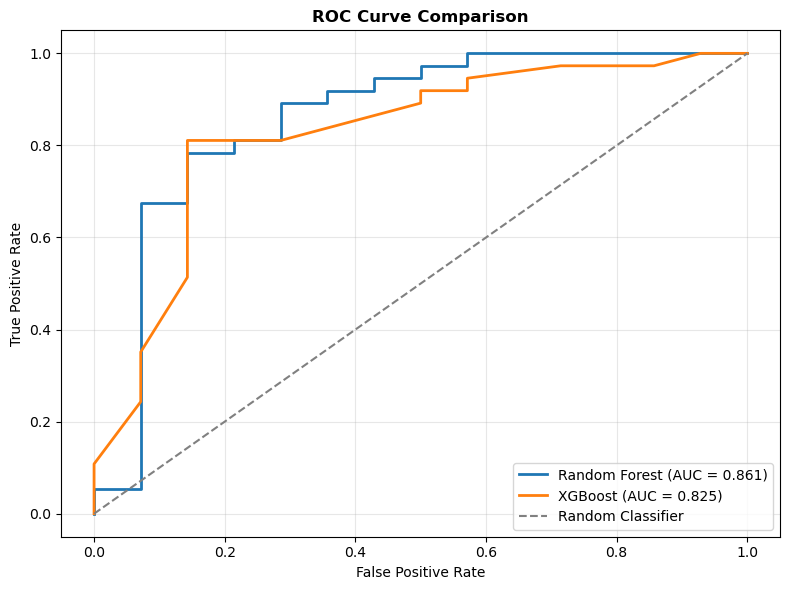


✓ ROC curve saved successfully.


In [4]:
# -----------------------------------
# Load Dataset
# -----------------------------------
df = pd.read_excel(
    r'D:\Thesis\Main\Data\GW table\Dataset_binary1.xlsx'
)

feature_cols = [
    'Rainfall',
    'Soil',
    'Geology',
    'DEM',
    'Drainage_Density',
    'Slope',
    'Lineament_Density',
    'LULC',
    'TWI'
]

X = df[feature_cols].values
y = df['Recharge_Class'].values

# # -----------------------------------
# # Handle class imbalance
# # -----------------------------------
# count_0 = np.sum(y == 0)
# count_1 = np.sum(y == 1)

# scale_pos_weight = (
#     count_0 / count_1
#     if count_1 > 0
#     else 1.0
# )

print("scale_pos_weight =", scale_pos_weight)

# -----------------------------------
# Random Forest
# -----------------------------------
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features='sqrt',
    bootstrap=True,
    oob_score=True,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# -----------------------------------
# XGBoost
# -----------------------------------
xgb_model = xgb.XGBClassifier(
    n_estimators=30,
    max_depth=3,
    learning_rate=0.05,
    subsample=1,
    colsample_bytree=1,
    min_child_weight=1,
    gamma=0,
    reg_alpha=0,
    reg_lambda=1,
    scale_pos_weight=scale_pos_weight,
    objective='binary:logistic',
    random_state=42,
    n_jobs=-1
)

# -----------------------------------
# 5-Fold Stratified CV
# -----------------------------------
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# -----------------------------------
# Evaluation Function
# -----------------------------------
def evaluate_model(model, X, y):

    metrics = {
        'accuracy': [],
        'precision': [],
        'recall': [],
        'f1': [],
        'roc_auc': [],
        'kappa': [],
        'mcc': []
    }

    all_y_true = []
    all_y_prob = []

    for train_idx, test_idx in skf.split(X, y):

        X_train = X[train_idx]
        X_test = X[test_idx]

        y_train = y[train_idx]
        y_test = y[test_idx]

        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        metrics['accuracy'].append(
            accuracy_score(y_test, y_pred)
        )

        metrics['precision'].append(
            precision_score(y_test, y_pred)
        )

        metrics['recall'].append(
            recall_score(y_test, y_pred)
        )

        metrics['f1'].append(
            f1_score(y_test, y_pred)
        )

        metrics['roc_auc'].append(
            roc_auc_score(y_test, y_prob)
        )

        metrics['kappa'].append(
            cohen_kappa_score(y_test, y_pred)
        )

        metrics['mcc'].append(
            matthews_corrcoef(y_test, y_pred)
        )

        all_y_true.extend(y_test)
        all_y_prob.extend(y_prob)

    results = {
        k: (np.mean(v), np.std(v))
        for k, v in metrics.items()
    }

    return (
        results,
        np.array(all_y_true),
        np.array(all_y_prob)
    )

# -----------------------------------
# Run Models
# -----------------------------------
rf_results, rf_true, rf_prob = evaluate_model(
    rf_model,
    X,
    y
)

xgb_results, xgb_true, xgb_prob = evaluate_model(
    xgb_model,
    X,
    y
)

# -----------------------------------
# Comparison Table
# -----------------------------------
comparison_df = pd.DataFrame({

    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score',
        'ROC AUC',
        'Kappa',
        'MCC'
    ],

    'Random Forest (Mean ± Std)': [

        f"{rf_results['accuracy'][0]:.4f} ± {rf_results['accuracy'][1]:.4f}",
        f"{rf_results['precision'][0]:.4f} ± {rf_results['precision'][1]:.4f}",
        f"{rf_results['recall'][0]:.4f} ± {rf_results['recall'][1]:.4f}",
        f"{rf_results['f1'][0]:.4f} ± {rf_results['f1'][1]:.4f}",
        f"{rf_results['roc_auc'][0]:.4f} ± {rf_results['roc_auc'][1]:.4f}",
        f"{rf_results['kappa'][0]:.4f} ± {rf_results['kappa'][1]:.4f}",
        f"{rf_results['mcc'][0]:.4f} ± {rf_results['mcc'][1]:.4f}"
    ],

    'XGBoost (Mean ± Std)': [

        f"{xgb_results['accuracy'][0]:.4f} ± {xgb_results['accuracy'][1]:.4f}",
        f"{xgb_results['precision'][0]:.4f} ± {xgb_results['precision'][1]:.4f}",
        f"{xgb_results['recall'][0]:.4f} ± {xgb_results['recall'][1]:.4f}",
        f"{xgb_results['f1'][0]:.4f} ± {xgb_results['f1'][1]:.4f}",
        f"{xgb_results['roc_auc'][0]:.4f} ± {xgb_results['roc_auc'][1]:.4f}",
        f"{xgb_results['kappa'][0]:.4f} ± {xgb_results['kappa'][1]:.4f}",
        f"{xgb_results['mcc'][0]:.4f} ± {xgb_results['mcc'][1]:.4f}"
    ]
})

print(comparison_df)

comparison_df.to_csv(
    r'D:\Thesis\Main\Models\Model_Comparison_KFold_ProperNEW.csv',
    index=False
)

# -----------------------------------
# Bar Chart Comparison
# -----------------------------------
metrics_map = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1-Score': 'f1',
    'ROC AUC': 'roc_auc',
    'Kappa': 'kappa',
    'MCC': 'mcc'
}

metrics_list = list(metrics_map.keys())

rf_mean = [
    rf_results[metrics_map[m]][0]
    for m in metrics_list
]

rf_std = [
    rf_results[metrics_map[m]][1]
    for m in metrics_list
]

xgb_mean = [
    xgb_results[metrics_map[m]][0]
    for m in metrics_list
]

xgb_std = [
    xgb_results[metrics_map[m]][1]
    for m in metrics_list
]

x = np.arange(len(metrics_list))
width = 0.35

fig, ax = plt.subplots(figsize=(12,6))

ax.bar(
    x - width/2,
    rf_mean,
    width,
    yerr=rf_std,
    capsize=5,
    label='Random Forest'
)

ax.bar(
    x + width/2,
    xgb_mean,
    width,
    yerr=xgb_std,
    capsize=5,
    label='XGBoost'
)

ax.set_ylabel('Score')
ax.set_xlabel('Metric')
ax.set_title(
    'Random Forest vs XGBoost (5-Fold Cross Validation)',
    fontweight='bold'
)

ax.set_xticks(x)
ax.set_xticklabels(
    metrics_list,
    rotation=45,
    ha='right'
)

ax.set_ylim(0,1.1)
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()

# #plt.savefig(
#     r'D:\Thesis\Main\Models\Model_Comparison_KFold_Proper_Chart.png',
#     dpi=600,
#     bbox_inches='tight'
# )

plt.close()

# -----------------------------------
# ROC Curve
# -----------------------------------
rf_fpr, rf_tpr, _ = roc_curve(
    rf_true,
    rf_prob
)

xgb_fpr, xgb_tpr, _ = roc_curve(
    xgb_true,
    xgb_prob
)

rf_auc = auc(
    rf_fpr,
    rf_tpr
)

xgb_auc = auc(
    xgb_fpr,
    xgb_tpr
)

plt.figure(figsize=(8,6))

plt.plot(
    rf_fpr,
    rf_tpr,
    linewidth=2,
    label=f'Random Forest (AUC = {rf_auc:.3f})'
)

plt.plot(
    xgb_fpr,
    xgb_tpr,
    linewidth=2,
    label=f'XGBoost (AUC = {xgb_auc:.3f})'
)

plt.plot(
    [0,1],
    [0,1],
    '--',
    color='gray',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(
    'ROC Curve Comparison',
    fontweight='bold'
)

plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.tight_layout()

# plt.savefig(
#     r'D:\Thesis\Main\Models\ROC_Curve_RF_XGB.png',
#     dpi=600,
#     bbox_inches='tight'
# )

plt.show()

print("\n✓ ROC curve saved successfully.")

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, cohen_kappa_score, matthews_corrcoef,
    confusion_matrix, classification_report
)
import joblib

# -----------------------------
# Load dataset
# -----------------------------
df = pd.read_excel(r'D:\Thesis\Main\Data\GW table\Dataset_binary1.xlsx')
feature_cols = ['Rainfall', 'Soil', 'Geology', 'DEM', 'Drainage_Density',
                'Slope', 'Lineament_Density', 'LULC', 'TWI']
X = df[feature_cols]
y = df['Recharge_Class']  # Binary: 0 = Low, 1 = High

# -----------------------------
# Train-test split (80-20)
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# -----------------------------
# Random Forest Classifier
# -----------------------------
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features='sqrt',
    bootstrap=True,
    oob_score=True,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
joblib.dump(rf_model, r'D:\Thesis\Main\Models\Random Forest\RF_Final_80_20.pkl')

# -----------------------------
# XGBoost Classifier (multi:softmax for binary consistency)
# -----------------------------
count_0 = (y_train == 0).sum()
count_1 = (y_train == 1).sum()
scale_pos_weight = count_0 / count_1 if count_1 > 0 else 1.0

xgb_model = xgb.XGBClassifier(
    n_estimators=30,
    max_depth=3,
    learning_rate=0.05,
    subsample=1,
    colsample_bytree=1,
    min_child_weight=1,
    gamma=0,
    reg_alpha=0,
    reg_lambda=1,
    scale_pos_weight=scale_pos_weight,
    objective='binary:logistic',  # correct for binary classification
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train, y_train)
joblib.dump(xgb_model, r'D:\Thesis\Main\Models\XGBoost\XGBoost_Final_80_20.pkl')

print("✓ Both models trained and saved as .pkl files")

# -----------------------------
# Predictions
# -----------------------------
rf_pred = rf_model.predict(X_test)
xgb_pred = xgb_model.predict(X_test)

rf_pred_proba = rf_model.predict_proba(X_test)[:, 1]
# For multi:softmax, convert predicted class to probability 1
xgb_pred_proba = np.where(xgb_pred == 1, 1, 0)

# -----------------------------
# Metrics calculation
# -----------------------------
metrics = {
    'Model': ['Random Forest', 'XGBoost'],
    'Accuracy': [
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, xgb_pred)
    ],
    'Precision': [
        precision_score(y_test, rf_pred, average='weighted'),
        precision_score(y_test, xgb_pred, average='weighted')
    ],
    'Recall': [
        recall_score(y_test, rf_pred, average='weighted'),
        recall_score(y_test, xgb_pred, average='weighted')
    ],
    'F1-Score': [
        f1_score(y_test, rf_pred, average='weighted'),
        f1_score(y_test, xgb_pred, average='weighted')
    ],
    'ROC AUC': [
        roc_auc_score(y_test, rf_pred_proba),
        roc_auc_score(y_test, xgb_pred_proba)
    ],
    'Kappa': [
        cohen_kappa_score(y_test, rf_pred),
        cohen_kappa_score(y_test, xgb_pred)
    ],
    'MCC': [
        matthews_corrcoef(y_test, rf_pred),
        matthews_corrcoef(y_test, xgb_pred)
    ],
    'OOB Error': [
        1 - rf_model.oob_score_ if hasattr(rf_model, 'oob_score_') else np.nan,
        np.nan
    ]
}

comparison_df = pd.DataFrame(metrics)

# -----------------------------
# Display results
# -----------------------------
print("="*80)
print("80-20 SPLIT MODEL COMPARISON")
print("="*80)
print(comparison_df.to_string(index=False))

# -----------------------------
# Save comparison CSV
# -----------------------------
comparison_df.to_csv(r'D:\Thesis\Main\Models\Model_Comparison_80_20.csv', index=False)
print("\n✓ Comparison CSV saved: Model_Comparison_80_20.csv")

# -----------------------------
# Visualize comparison (bar chart)
# -----------------------------
fig, ax = plt.subplots(figsize=(12, 6))
comparison_df_plot = comparison_df.set_index('Model').drop('OOB Error', axis=1)
comparison_df_plot.T.plot(kind='bar', ax=ax, width=0.7)
ax.set_ylabel('Score', fontsize=12)
ax.set_xlabel('Metric', fontsize=12)
ax.set_title('Random Forest vs XGBoost (80-20 Split) Performance', fontsize=14, fontweight='bold')
ax.legend(title='Model', fontsize=10)
ax.set_ylim([0, 1.1])
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(r'D:\Thesis\Main\Models\Model_Comparison_80_20_Chart.png', dpi=300, bbox_inches='tight')
plt.close()
print("✓ Comparison chart saved: Model_Comparison_80_20_Chart.png")



✓ Both models trained and saved as .pkl files
80-20 SPLIT MODEL COMPARISON
        Model  Accuracy  Precision   Recall  F1-Score  ROC AUC    Kappa      MCC  OOB Error
Random Forest  0.818182   0.818182 0.818182  0.818182 0.958333 0.541667 0.541667       0.25
      XGBoost  0.818182   0.818182 0.818182  0.818182 0.770833 0.541667 0.541667        NaN

✓ Comparison CSV saved: Model_Comparison_80_20.csv
✓ Comparison chart saved: Model_Comparison_80_20_Chart.png


In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Confusion matrices
cm_rf = confusion_matrix(y_test, rf_pred)
cm_xgb = confusion_matrix(y_test, xgb_pred)

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Random Forest
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, 
                                 display_labels=['Low', 'High'])
disp_rf.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title('Random Forest - Confusion Matrix', fontsize=12, fontweight='bold')

# XGBoost
disp_xgb = ConfusionMatrixDisplay(confusion_matrix=cm_xgb,
                                  display_labels=['Low', 'High'])
disp_xgb.plot(ax=axes[1], cmap='Greens', values_format='d')
axes[1].set_title('XGBoost - Confusion Matrix', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig(r'D:\Thesis\Main\Models\Confusion_Matrices.png', dpi=300, bbox_inches='tight')
plt.close()
print("✓ Confusion matrices saved: Confusion_Matrices.png")


✓ Confusion matrices saved: Confusion_Matrices.png


In [25]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# For binary classification, we only need probability of class 1
# Make sure these are 1D arrays of probabilities
rf_proba = rf_model.predict_proba(X_test)[:, 1]
xgb_proba = xgb_model.predict_proba(X_test)[:, 1]

# Compute ROC curve and AUC
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_proba)
roc_auc_rf = auc(fpr_rf, tpr_rf)

fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_proba)
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Random Forest ROC
axes[0].plot(fpr_rf, tpr_rf, color='blue', label=f'AUC = {roc_auc_rf:.3f}')
axes[0].plot([0, 1], [0, 1], 'k--', label='Random Chance')
axes[0].set_xlabel('False Positive Rate', fontsize=12)
axes[0].set_ylabel('True Positive Rate', fontsize=12)
axes[0].set_title('Random Forest - ROC Curve', fontsize=12, fontweight='bold')
axes[0].legend(loc='lower right')
axes[0].grid(alpha=0.3)

# XGBoost ROC
axes[1].plot(fpr_xgb, tpr_xgb, color='green', label=f'AUC = {roc_auc_xgb:.3f}')
axes[1].plot([0, 1], [0, 1], 'k--', label='Random Chance')
axes[1].set_xlabel('False Positive Rate', fontsize=12)
axes[1].set_ylabel('True Positive Rate', fontsize=12)
axes[1].set_title('XGBoost - ROC Curve', fontsize=12, fontweight='bold')
axes[1].legend(loc='lower right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(r'D:\Thesis\Main\Models\ROC_Curves.png', dpi=300, bbox_inches='tight')
plt.close()
print("✓ ROC curves saved: ROC_Curves.png")


✓ ROC curves saved: ROC_Curves.png


In [26]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, cohen_kappa_score
)

# -----------------------------
# Compute feature importance for RF
# -----------------------------
feature_importance = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

# Take top 5 features
feature_importance_top5 = feature_importance.head(5)

# -----------------------------
# Generate comprehensive report
# -----------------------------
report = f"""
{'='*80}
GROUNDWATER RECHARGE MAPPING - MODEL EVALUATION REPORT
Rajshahi District, Bangladesh
{'='*80}

1. DATASET SUMMARY
   - Total samples: {len(df)}
   - Training samples: {len(X_train)}
   - Test samples: {len(X_test)}
   - Number of features: {len(feature_cols)}
   - Class distribution: {dict(pd.Series(y).value_counts())}

2. RANDOM FOREST PERFORMANCE
   - Test Accuracy: {accuracy_score(y_test, rf_pred):.4f}
   - Precision: {precision_score(y_test, rf_pred, average='weighted'):.4f}
   - Recall: {recall_score(y_test, rf_pred, average='weighted'):.4f}
   - F1-Score: {f1_score(y_test, rf_pred, average='weighted'):.4f}
   - ROC AUC: {roc_auc_score(y_test, rf_pred_proba):.4f}
   - Cohen's Kappa: {cohen_kappa_score(y_test, rf_pred):.4f}
   - OOB Score: {rf_model.oob_score_:.4f}
   - OOB Error: {1 - rf_model.oob_score_:.4f}

3. XGBOOST PERFORMANCE
   - Test Accuracy: {accuracy_score(y_test, xgb_pred):.4f}
   - Precision: {precision_score(y_test, xgb_pred, average='weighted'):.4f}
   - Recall: {recall_score(y_test, xgb_pred, average='weighted'):.4f}
   - F1-Score: {f1_score(y_test, xgb_pred, average='weighted'):.4f}
   - ROC AUC: {roc_auc_score(y_test, xgb_pred_proba):.4f}
   - Cohen's Kappa: {cohen_kappa_score(y_test, xgb_pred):.4f}

4. BEST MODEL
   {'Random Forest' if accuracy_score(y_test, rf_pred) > accuracy_score(y_test, xgb_pred) else 'XGBoost'}

5. TOP 5 IMPORTANT FEATURES (Random Forest)
{feature_importance_top5.to_string(index=False)}

{'='*80}
"""

# -----------------------------
# Save report
# -----------------------------
report_path = r'D:\Thesis\Main\Models\Model_Evaluation_Report.txt'
with open(report_path, 'w') as f:
    f.write(report)

print(report)
print(f"\n✓ Report saved: {report_path}")



GROUNDWATER RECHARGE MAPPING - MODEL EVALUATION REPORT
Rajshahi District, Bangladesh

1. DATASET SUMMARY
   - Total samples: 51
   - Training samples: 40
   - Test samples: 11
   - Number of features: 9
   - Class distribution: {1: np.int64(37), 0: np.int64(14)}

2. RANDOM FOREST PERFORMANCE
   - Test Accuracy: 0.8182
   - Precision: 0.8182
   - Recall: 0.8182
   - F1-Score: 0.8182
   - ROC AUC: 0.9583
   - Cohen's Kappa: 0.5417
   - OOB Score: 0.7500
   - OOB Error: 0.2500

3. XGBOOST PERFORMANCE
   - Test Accuracy: 0.8182
   - Precision: 0.8182
   - Recall: 0.8182
   - F1-Score: 0.8182
   - ROC AUC: 0.7708
   - Cohen's Kappa: 0.5417

4. BEST MODEL
   XGBoost

5. TOP 5 IMPORTANT FEATURES (Random Forest)
         Feature  Importance
         Geology    0.270101
             DEM    0.216880
        Rainfall    0.173885
             TWI    0.121901
Drainage_Density    0.096792



✓ Report saved: D:\Thesis\Main\Models\Model_Evaluation_Report.txt
